# Optimisation différentiable : résolution par la méthode de quasi-Newton (BFGS)

**Niveau :** 4ᵉ année — Sciences des Données et Intelligence Artificielle  
**Outils :** NumPy, SymPy, Pandas, Matplotlib

---

## Plan du notebook

1. Introduction
2. Énoncé de l'exercice
3. Résolution mathématique
4. Implémentation Python
5. Résultats et visualisations
6. Interprétation et conclusion

## Partie 1 — Introduction

### 1.1 L'optimisation différentiable

On cherche le minimum d'une fonction dérivable $f : \mathbb{R}^n \to \mathbb{R}$ :

$$\min_{x \in \mathbb{R}^n} f(x).$$

Les algorithmes de descente construisent une suite $x_{k+1} = x_k + \alpha_k d_k$, où $d_k$ est une **direction de descente** et $\alpha_k > 0$ un **pas**.

### 1.2 Limite de la méthode de Newton

La méthode de Newton utilise $d_k = -H_f(x_k)^{-1}\nabla f(x_k)$. Elle converge très vite (quadratiquement), mais elle exige à chaque itération :

- le calcul du **Hessien** exact, soit $O(n^2)$ dérivées secondes ;
- la résolution d'un **système linéaire**, soit $O(n^3)$ opérations ;
- un Hessien **défini positif** pour que $d_k$ soit une direction de descente.

### 1.3 Principe des méthodes de quasi-Newton

Les méthodes de quasi-Newton **n'évaluent jamais le Hessien**. Elles construisent, à partir des seuls gradients, une approximation $B_k \approx H_f(x_k)$ (ou de son inverse $H_k \approx H_f(x_k)^{-1}$) mise à jour à chaque itération par une correction de rang faible. L'information de courbure est « apprise » en observant comment le gradient varie d'une itération à l'autre.

On note

$$s_k = x_{k+1} - x_k, \qquad y_k = \nabla f(x_{k+1}) - \nabla f(x_k).$$

### 1.4 L'algorithme BFGS

BFGS (Broyden–Fletcher–Goldfarb–Shanno) est la méthode de quasi-Newton la plus utilisée. En notant $V_k = I - \rho_k\, y_k s_k^\top$ et $\rho_k = \dfrac{1}{y_k^\top s_k}$, la mise à jour de l'approximation de l'**inverse** du Hessien est :

$$\boxed{\,H_{k+1} = \left(I - \rho_k s_k y_k^\top\right) H_k \left(I - \rho_k y_k s_k^\top\right) + \rho_k\, s_k s_k^\top\,}$$

et la direction de descente est $d_k = -H_k \nabla f(x_k)$. Comme $H_k$ approche directement l'inverse du Hessien, **aucun système linéaire n'est à résoudre** : un simple produit matrice-vecteur ($O(n^2)$) suffit.

**Propriété :** la convergence est **superlinéaire** près d'un minimum non dégénéré, c'est-à-dire plus rapide que linéaire mais un peu moins rapide que la convergence quadratique de Newton.

## Partie 2 — Énoncé de l'exercice

On considère la même fonction de deux variables que pour la méthode de Newton :

$$f(x,y) = x^4 + y^4 - 4xy.$$

**Questions :**

1. Calculer le gradient et la matrice Hessienne de $f$, puis déterminer et classifier ses points critiques.
2. Établir l'équation sécante et la formule de mise à jour BFGS.
3. Appliquer l'algorithme BFGS à partir de $x_0 = (2;\ 1{,}5)$ avec $H_0 = I_2$, une recherche linéaire d'Armijo et le critère d'arrêt $\|\nabla f(x_k)\|_2 < 10^{-10}$.
4. Présenter le tableau des itérations, la courbe de convergence et le chemin suivi sur les courbes de niveau.
5. Comparer BFGS avec la méthode de Newton et avec la descente de gradient.
6. Discuter les limites de la méthode.

## Partie 3 — Résolution mathématique

### 3.1 Fonction objectif, gradient et Hessien

$$f(x,y) = x^4 + y^4 - 4xy, \qquad \nabla f(x,y) = \begin{pmatrix} 4x^3 - 4y \\ 4y^3 - 4x \end{pmatrix}, \qquad H_f(x,y) = \begin{pmatrix} 12x^2 & -4 \\ -4 & 12y^2 \end{pmatrix}.$$

### 3.2 Points critiques et conditions d'optimalité

La condition nécessaire $\nabla f = 0$ donne $y = x^3$ et $x = y^3$, d'où $x = x^9$, soit $x \in \{0, 1, -1\}$ :

| Point | $\det H_f$ | Valeurs propres de $H_f$ | Nature | $f$ |
|---|---|---|---|---|
| $(0,0)$ | $-16$ | $\pm 4$ | point selle | $0$ |
| $(1,1)$ | $128$ | $8,\ 16$ | minimum local strict | $-2$ |
| $(-1,-1)$ | $128$ | $8,\ 16$ | minimum local strict | $-2$ |

Comme $f \to +\infty$ à l'infini, $-2$ est le minimum global, atteint en $(1,1)$ et $(-1,-1)$.

**Remarque.** BFGS n'utilise pas le Hessien pour avancer ; on le calcule ici uniquement pour **vérifier** les résultats.

### 3.3 Équation sécante

Un développement de Taylor du gradient autour de $x_{k+1}$ donne
$$\nabla f(x_k) \approx \nabla f(x_{k+1}) + H_f(x_{k+1})(x_k - x_{k+1}) \;\Longrightarrow\; H_f(x_{k+1})\, s_k \approx y_k.$$

On impose donc à la nouvelle approximation de vérifier exactement cette relation, appelée **équation sécante** :

$$B_{k+1}\, s_k = y_k \qquad \Longleftrightarrow \qquad H_{k+1}\, y_k = s_k.$$

BFGS choisit, parmi toutes les matrices symétriques vérifiant cette équation, celle qui est la plus proche de $H_k$ (au sens d'une norme pondérée). Cela conduit à la formule du paragraphe 1.4.

### 3.4 Condition de courbure et définie positivité

Si $H_k$ est symétrique définie positive, alors $H_{k+1}$ l'est aussi **si et seulement si** la **condition de courbure** est satisfaite :

$$s_k^\top y_k > 0.$$

Dans ce cas $d_k = -H_k \nabla f(x_k)$ est bien une direction de descente, car $\nabla f(x_k)^\top d_k = -\nabla f(x_k)^\top H_k \nabla f(x_k) < 0$.

Cette condition est garantie par les conditions de Wolfe. Dans ce notebook, on utilise une recherche linéaire d'**Armijo** (plus simple), et on **ignore la mise à jour** lorsque $s_k^\top y_k$ n'est pas suffisamment positif : $H$ reste alors définie positive.

### 3.5 Recherche linéaire d'Armijo (backtracking)

Le pas $\alpha_k$ est le premier élément de la suite $\alpha^{(0)}, \tfrac12\alpha^{(0)}, \tfrac14\alpha^{(0)}, \dots$ (avec $\alpha^{(0)}=1$) qui vérifie la **condition de décroissance suffisante** :

$$f(x_k + \alpha d_k) \le f(x_k) + c_1\, \alpha\, \nabla f(x_k)^\top d_k, \qquad c_1 = 10^{-4}.$$

### 3.6 Point initial et algorithme

On choisit $x_0 = (2;\ 1{,}5)$ et $H_0 = I_2$ : pour la première itération, $d_0 = -\nabla f(x_0)$ (direction de plus forte descente).

1. Initialiser $x_0$, $H_0 = I$, $\varepsilon = 10^{-10}$.
2. Pour $k = 0, 1, 2, \dots$ :
   1. calculer $g_k = \nabla f(x_k)$ ; si $\|g_k\|_2 < \varepsilon$, arrêter ;
   2. direction : $d_k = -H_k g_k$ ;
   3. pas $\alpha_k$ par recherche linéaire d'Armijo (pour $k=0$, pas initial $\alpha^{(0)}=\min(1,\,1/\|g_0\|)$ car $H_0=I$ ne contient aucune information d'échelle) ;
   4. mise à jour : $x_{k+1} = x_k + \alpha_k d_k$, $s_k = \alpha_k d_k$, $y_k = g_{k+1} - g_k$ ;
   5. si $s_k^\top y_k > 0$, mise à jour BFGS de $H_{k+1}$ ; sinon $H_{k+1} = H_k$.

## Partie 4 — Implémentation Python

### 4.1 Imports et réglages

In [1]:
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda v: f"{v:.10g}")
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

### 4.2 Calcul symbolique (SymPy) et fonctions numériques

Le Hessien exact sert uniquement à **vérifier** les résultats ; l'algorithme BFGS n'en a pas besoin.

In [2]:
x, y = sp.symbols("x y", real=True)
f_sym    = x**4 + y**4 - 4*x*y
grad_sym = sp.Matrix([sp.diff(f_sym, x), sp.diff(f_sym, y)])
hess_sym = sp.hessian(f_sym, (x, y))

print("f(x,y) =", f_sym)
sp.pprint(grad_sym)
sp.pprint(hess_sym)

f_num    = sp.lambdify((x, y), f_sym, "numpy")
grad_num = sp.lambdify((x, y), grad_sym, "numpy")
hess_num = sp.lambdify((x, y), hess_sym, "numpy")

def f(p):    return float(f_num(p[0], p[1]))
def grad(p): return np.array(grad_num(p[0], p[1]), dtype=float).ravel()
def hess(p): return np.array(hess_num(p[0], p[1]), dtype=float)   # utilisé uniquement pour vérifier

f(x,y) = x**4 - 4*x*y + y**4
⎡   3       ⎤
⎢4⋅x  - 4⋅y ⎥
⎢           ⎥
⎢          3⎥
⎣-4⋅x + 4⋅y ⎦
⎡    2       ⎤
⎢12⋅x    -4  ⎥
⎢            ⎥
⎢           2⎥
⎣ -4    12⋅y ⎦


### 4.3 Vérification des points critiques

In [3]:
sols = sp.solve(list(grad_sym), (x, y), dict=True)
rows = []
for s in sols:
    H = hess_sym.subs(s)
    eigs = list(H.eigenvals().keys())
    nature = ("minimum local strict" if all(e > 0 for e in eigs)
              else "maximum local strict" if all(e < 0 for e in eigs) else "point selle")
    rows.append({"point": (s[x], s[y]), "f": f_sym.subs(s), "det(H)": H.det(),
                 "valeurs propres": eigs, "nature": nature})
pd.DataFrame(rows)

,point,f,det(H),valeurs propres,nature
0,"(-1, -1)",-2,128,"[16, 8]",minimum local strict
1,"(0, 0)",0,-16,"[-4, 4]",point selle
2,"(1, 1)",-2,128,"[16, 8]",minimum local strict


### 4.4 Étape 1 — Mise à jour BFGS de l'inverse du Hessien

On programme la formule $H_{k+1} = (I - \rho s y^\top)\, H_k\, (I - \rho y s^\top) + \rho\, s s^\top$ et on **vérifie numériquement** ses propriétés théoriques (équation sécante, symétrie, définie positivité) sur un exemple.

In [4]:
def bfgs_update(H, s, y):
    # Mise à jour BFGS de l'approximation H de l'inverse du Hessien.
    rho = 1.0 / (y @ s)
    I = np.eye(len(s))
    V = I - rho * np.outer(s, y)
    return V @ H @ V.T + rho * np.outer(s, s)

# Test sur un exemple avec s^T y > 0
s_test = np.array([0.5, -0.2])
y_test = np.array([1.0, 0.3])
H_test = bfgs_update(np.eye(2), s_test, y_test)

print("s^T y                    =", s_test @ y_test)
print("Equation sécante H y - s =", H_test @ y_test - s_test, " (attendu : 0)")
print("Symétrie  ||H - H^T||    =", np.linalg.norm(H_test - H_test.T))
print("Valeurs propres de H     =", np.linalg.eigvalsh(H_test), " (attendu : > 0)")

s^T y                    = 0.44
Equation sécante H y - s = [ 0.00000000e+00 -1.11022302e-16]  (attendu : 0)
Symétrie  ||H - H^T||    = 0.0
Valeurs propres de H     = [0.33719177 1.95464707]  (attendu : > 0)


### 4.5 Étape 2 — Recherche linéaire d'Armijo

In [5]:
def armijo(p, d, g, alpha0=1.0, c1=1e-4, facteur=0.5, max_red=60):
    # Backtracking : part de alpha0 et divise le pas par 2 jusqu'à la décroissance suffisante.
    alpha = alpha0
    f0, pente = f(p), g @ d              # pente < 0 pour une direction de descente
    for _ in range(max_red):
        if f(p + alpha * d) <= f0 + c1 * alpha * pente:
            return alpha
        alpha *= facteur
    return alpha

### 4.6 Étape 3 — Algorithme BFGS complet

Chaque itération suit les étapes : **gradient → direction → pas → mise à jour de $x$ → mise à jour de $H$ → test de convergence**.

In [6]:
def bfgs(p0, tol=1e-10, max_iter=200, H0=None):
    p = np.array(p0, dtype=float)
    n = len(p)
    H = np.eye(n) if H0 is None else H0.copy()
    g = grad(p)
    historique, Hs = [], []

    for k in range(max_iter + 1):
        norme_g = np.linalg.norm(g)
        historique.append({"k": k, "x": p[0], "y": p[1], "f(x,y)": f(p),
                           "||grad||": norme_g, "alpha": np.nan, "s^T y": np.nan, "maj H": None})
        Hs.append(H.copy())

        if norme_g < tol or k == max_iter:     # 5. critère de convergence
            break

        d = -H @ g                              # 2. direction (produit matrice-vecteur)
        if g @ d >= 0:                          # sécurité : H doit rester définie positive
            H, d = np.eye(n), -g
        # 3. recherche linéaire ; 1re itération : H0 = I ne contient aucune échelle -> pas initial min(1, 1/||g||)
        alpha0 = min(1.0, 1.0 / norme_g) if k == 0 else 1.0
        alpha = armijo(p, d, g, alpha0)

        s = alpha * d                           # 4. mise à jour des variables
        p_new = p + s
        g_new = grad(p_new)
        yk = g_new - g

        sy = s @ yk
        historique[-1]["alpha"], historique[-1]["s^T y"] = alpha, sy
        maj = sy > 1e-12 * np.linalg.norm(s) * np.linalg.norm(yk)
        historique[-1]["maj H"] = bool(maj)
        if maj:
            H = bfgs_update(H, s, yk)           # condition de courbure OK -> mise à jour BFGS
        # sinon : on conserve H (mise à jour ignorée)

        p, g = p_new, g_new

    return pd.DataFrame(historique), Hs

## Partie 5 — Résultats et visualisations

### 5.1 Détail de la première itération (recherche linéaire)

Pour $H_0 = I$ : $d_0 = -\nabla f(x_0) = -(26;\ 5{,}5)$ et $\nabla f(x_0)^\top d_0 = -706{,}25$. Le pas complet $\alpha = 1$ mène à $(-24;\ -4)$ où $f$ est énorme : il est refusé. Comme $H_0 = I$ ne donne aucune information d'échelle, on débute à la première itération avec $\alpha^{(0)} = \min(1, 1/\|g_0\|)$ (convention classique, Nocedal & Wright).

In [7]:
p0 = np.array([2.0, 1.5])
g0 = grad(p0); d0 = -g0
print("grad(x0) =", g0, "  d0 =", d0, "  grad^T d0 =", g0 @ d0, "  f(x0) =", f(p0))

alpha_init = min(1.0, 1.0 / np.linalg.norm(g0))
lignes = []
for nom, a in [("pas complet", 1.0), ("pas initial 1/||g0||", alpha_init)]:
    f_new = f(p0 + a * d0)
    seuil = f(p0) + 1e-4 * a * (g0 @ d0)
    lignes.append({"essai": nom, "alpha": a, "x0 + alpha d0": tuple(np.round(p0 + a * d0, 4)),
                   "f(x0 + alpha d0)": f_new, "seuil Armijo": seuil, "accepté": f_new <= seuil})
pd.DataFrame(lignes)

grad(x0) = [26.   5.5]   d0 = [-26.   -5.5]   grad^T d0 = -706.25   f(x0) = 9.0625


,essai,alpha,x0 + alpha d0,f(x0 + alpha d0),seuil Armijo,accepté
0,pas complet,1,"(-24.0, -4.0)",331648,8.991875,False
1,pas initial 1/||g0||,0.03762883474,"(1.0217, 1.293)",-1.399252994,9.059842464,True


### 5.2 Tableau des itérations de BFGS

In [8]:
res, Hs = bfgs([2.0, 1.5], tol=1e-10)
res

,k,x,y,"f(x,y)",||grad||,alpha,s^T y,maj H
0,0,2,1.5,9.0625,26.57536453,0.03762883474,26.51848605,True
1,1,1.021650297,1.293041409,-1.399252994,4.650281432,0.125,4.39513215,True
2,2,1.04201276,0.7019703522,-1.504092288,3.27165523,1,0.4452006331,True
3,3,1.008391048,0.9187757908,-1.959364656,1.024225078,1,0.1479214651,True
4,4,0.9994826607,1.029249215,-1.994703944,0.3837411702,1,0.01242665442,True
5,5,1.000867929,0.9979783029,-1.999963968,0.03330178122,1,6.330648932e-05,True
6,6,1.000466327,1.000111736,-1.999998828,0.00517821064,1,4.903239998e-07,True
7,7,1.000272712,1.000133862,-1.999999592,0.002786134642,1,7.197721904e-07,True
8,8,1.000013566,1.000031201,-1.999999995,0.0003224077508,1,8.276318024e-09,True
9,9,0.9999997312,1.000003796,-2,5.013301053e-05,1,1.769237961e-10,True


### 5.3 Analyse de la vitesse de convergence

Le minimum exact est $x^\* = (1,1)$. On calcule $e_k = \|x_k - x^\*\|_2$ et le rapport $e_{k+1}/e_k$. Pour une convergence **superlinéaire**, ce rapport tend vers $0$ ; pour une convergence linéaire, il tend vers une constante dans $]0,1[$. Les premières itérations, où $H_k$ est encore mal estimée, peuvent présenter des valeurs irrégulières.

In [9]:
x_star = np.array([1.0, 1.0])
res["erreur"] = np.linalg.norm(res[["x", "y"]].values - x_star, axis=1)
res["e_{k+1}/e_k"] = np.r_[res["erreur"].values[1:] / res["erreur"].values[:-1], np.nan]
res[["k", "erreur", "e_{k+1}/e_k"]]

,k,erreur,e_{k+1}/e_k
0,0,1.118033989,0.2628185727
1,1,0.2938400972,1.024286063
2,2,0.3009763163,0.2713053566
3,3,0.08165648682,0.3582543257
4,4,0.02925378962,0.07520828389
5,5,0.002200127315,0.2179541814
6,6,0.000479526948,0.6335295914
7,7,0.0003037945114,0.111992101
8,8,3.40225856e-05,0.1118593771
9,9,3.805745233e-06,0.02466289456


In [10]:
p_final = res[["x", "y"]].values[-1]
print(f"Itérations effectuées : {len(res)-1}")
print(f"Point final           : ({p_final[0]:.12f}, {p_final[1]:.12f})")
print(f"f au point final      : {res['f(x,y)'].values[-1]:.12f}   (valeur théorique : -2)")
print(f"||grad|| final        : {res['||grad||'].values[-1]:.2e}")
print("Valeurs propres du Hessien exact en x* :", np.linalg.eigvalsh(hess(p_final)), "(attendu : 8 et 16)")

Itérations effectuées : 13
Point final           : (1.000000000000, 1.000000000000)
f au point final      : -2.000000000000   (valeur théorique : -2)
||grad|| final        : 1.16e-12
Valeurs propres du Hessien exact en x* : [ 8. 16.] (attendu : 8 et 16)


### 5.4 Qualité de l'approximation de l'inverse du Hessien

Comparons la matrice $H_k$ construite par BFGS avec l'inverse exact du Hessien en $x^\*$, qui vaut
$$H_f(1,1)^{-1} = \begin{pmatrix}12&-4\\-4&12\end{pmatrix}^{-1} = \frac{1}{128}\begin{pmatrix}12&4\\4&12\end{pmatrix} = \begin{pmatrix}0{,}09375 & 0{,}03125\\ 0{,}03125 & 0{,}09375\end{pmatrix}.$$

In [11]:
H_bfgs  = Hs[-1]
H_exact = np.linalg.inv(hess(p_final))
print("H_k  (BFGS, dernière itération) =\n", H_bfgs)
print("Inverse exact du Hessien        =\n", H_exact)
print("Erreur relative ||H_k - H_exact|| / ||H_exact|| =",
      np.linalg.norm(H_bfgs - H_exact) / np.linalg.norm(H_exact))

H_k  (BFGS, dernière itération) =
 [[0.09360487 0.03128323]
 [0.03128323 0.09374206]]
Inverse exact du Hessien        =
 [[0.09375 0.03125]
 [0.03125 0.09375]]
Erreur relative ||H_k - H_exact|| / ||H_exact|| = 0.001093002984571771


### 5.5 Courbes de convergence

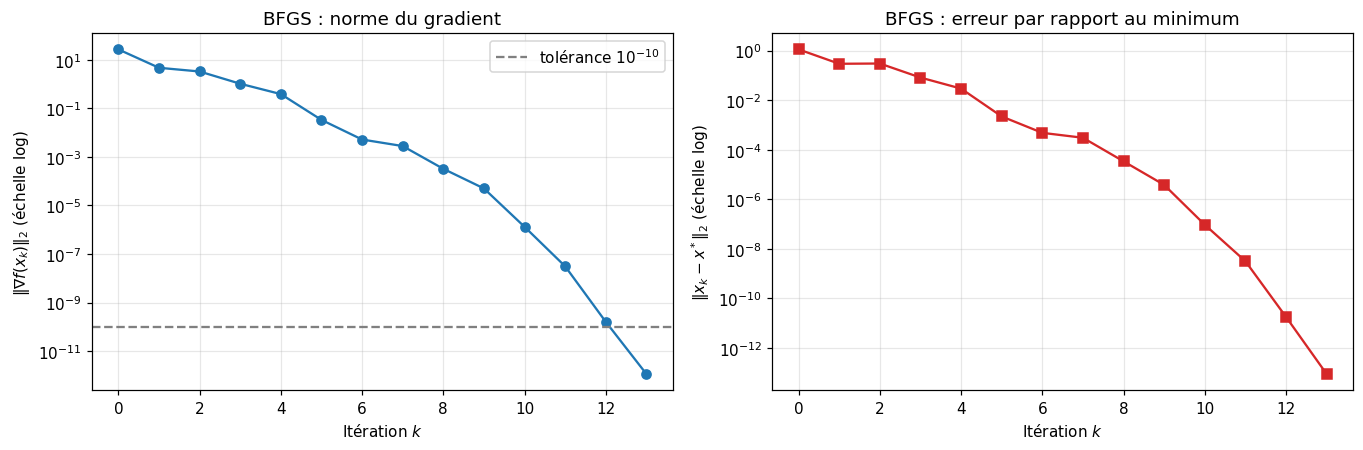

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2))

ax[0].semilogy(res["k"], res["||grad||"], "o-", color="tab:blue")
ax[0].axhline(1e-10, color="gray", ls="--", label="tolérance $10^{-10}$")
ax[0].set_title("BFGS : norme du gradient")
ax[0].set_xlabel("Itération $k$"); ax[0].set_ylabel(r"$\|\nabla f(x_k)\|_2$ (échelle log)")
ax[0].legend()

ax[1].semilogy(res["k"], res["erreur"].clip(lower=1e-17), "s-", color="tab:red")
ax[1].set_title("BFGS : erreur par rapport au minimum")
ax[1].set_xlabel("Itération $k$"); ax[1].set_ylabel(r"$\|x_k - x^*\|_2$ (échelle log)")

plt.tight_layout(); plt.show()

### 5.6 Courbes de niveau et chemin suivi par BFGS

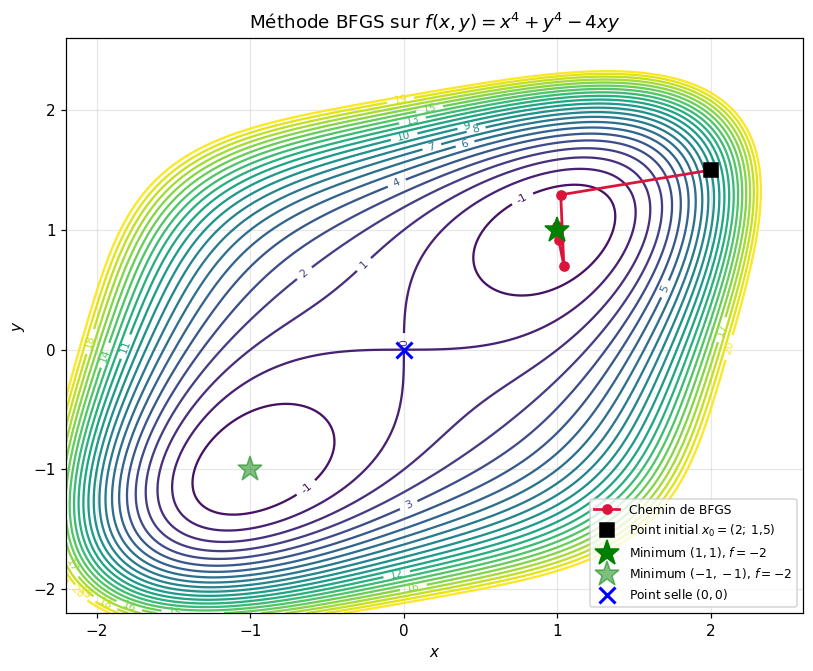

In [13]:
xs = np.linspace(-2.2, 2.6, 400); ys = np.linspace(-2.2, 2.6, 400)
X, Y = np.meshgrid(xs, ys); Z = f_num(X, Y)

fig, ax = plt.subplots(figsize=(7.5, 6.2))
cs = ax.contour(X, Y, Z, levels=np.linspace(-2, 20, 23), cmap="viridis")
ax.clabel(cs, inline=True, fontsize=7, fmt="%.0f")
ax.plot(res["x"], res["y"], "o-", color="crimson", lw=1.8, ms=6, label="Chemin de BFGS")
ax.plot(2.0, 1.5, "ks", ms=9, label="Point initial $x_0=(2;\\,1{,}5)$")
ax.plot(1, 1, "g*", ms=17, label="Minimum $(1,1)$, $f=-2$")
ax.plot(-1, -1, "g*", ms=17, alpha=0.5, label="Minimum $(-1,-1)$, $f=-2$")
ax.plot(0, 0, "bx", ms=11, mew=2, label="Point selle $(0,0)$")
ax.set_title("Méthode BFGS sur $f(x,y)=x^4+y^4-4xy$")
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### 5.7 Comparaison avec Newton et la descente de gradient

On programme les deux méthodes de référence avec les mêmes fonctions et la même tolérance.

In [14]:
def newton(p0, tol=1e-10, max_iter=50):
    p = np.array(p0, dtype=float); hist = []
    for k in range(max_iter + 1):
        g = grad(p); hist.append({"k": k, "x": p[0], "y": p[1], "f(x,y)": f(p), "||grad||": np.linalg.norm(g)})
        if np.linalg.norm(g) < tol or k == max_iter: break
        p = p + np.linalg.solve(hess(p), -g)
    return pd.DataFrame(hist)

def descente_gradient(p0, tol=1e-10, max_iter=5000):
    p = np.array(p0, dtype=float); hist = []
    for k in range(max_iter + 1):
        g = grad(p); hist.append({"k": k, "x": p[0], "y": p[1], "f(x,y)": f(p), "||grad||": np.linalg.norm(g), "alpha": np.nan})
        if np.linalg.norm(g) < tol or k == max_iter: break
        d = -g; a = armijo(p, d, g); hist[-1]["alpha"] = a; p = p + a * d
    return pd.DataFrame(hist)

res_newton = newton([2.0, 1.5])
res_gd     = descente_gradient([2.0, 1.5])

comparaison = pd.DataFrame({
    "méthode": ["Descente de gradient", "BFGS (quasi-Newton)", "Newton"],
    "itérations": [len(res_gd)-1, len(res)-1, len(res_newton)-1],
    "tolérance atteinte": [bool(r["||grad||"].values[-1] < 1e-10) for r in (res_gd, res, res_newton)],
    "f final": [r["f(x,y)"].values[-1] for r in (res_gd, res, res_newton)],
    "||grad|| final": [f"{r['||grad||'].values[-1]:.1e}" for r in (res_gd, res, res_newton)],
    "Hessien exact requis": ["non", "non", "oui"],
    "système linéaire à chaque itération": ["non", "non", "oui"],
})
comparaison

,méthode,itérations,tolérance atteinte,f final,||grad|| final,Hessien exact requis,système linéaire à chaque itération
0,Descente de gradient,5000,False,-2,5.9e-08,non,non
1,BFGS (quasi-Newton),13,True,-2,1.2e-12,non,non
2,Newton,6,True,-2,2.0e-13,oui,oui


In [15]:
print("Derniers pas de la descente de gradient :", res_gd["alpha"].dropna().values[-3:])
print("Limite de stabilité 2/lambda_max =", 2/16, "(lambda_max = 16 au minimum)")

Derniers pas de la descente de gradient : [0.125 0.125 0.125]
Limite de stabilité 2/lambda_max = 0.125 (lambda_max = 16 au minimum)


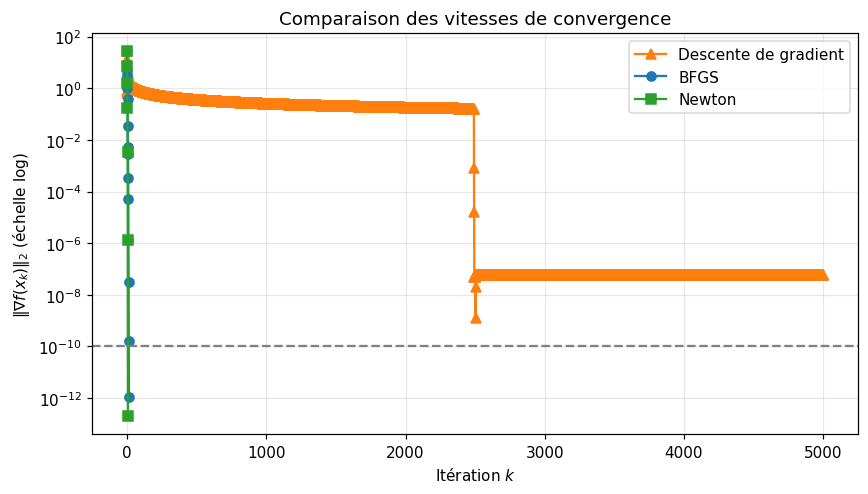

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.semilogy(res_gd["k"], res_gd["||grad||"], "^-", label="Descente de gradient", color="tab:orange")
ax.semilogy(res["k"], res["||grad||"], "o-", label="BFGS", color="tab:blue")
ax.semilogy(res_newton["k"], res_newton["||grad||"], "s-", label="Newton", color="tab:green")
ax.axhline(1e-10, color="gray", ls="--")
ax.set_title("Comparaison des vitesses de convergence")
ax.set_xlabel("Itération $k$"); ax.set_ylabel(r"$\|\nabla f(x_k)\|_2$ (échelle log)")
ax.legend(); plt.tight_layout(); plt.show()

## Partie 6 — Interprétation et conclusion

### 6.1 Bilan de la convergence

In [17]:
print(f"BFGS converge en {len(res)-1} itérations.")
print(f"Minimum trouvé : x* = ({p_final[0]:.10f}, {p_final[1]:.10f}),  f(x*) = {res['f(x,y)'].values[-1]:.10f}")

BFGS converge en 13 itérations.
Minimum trouvé : x* = (1.0000000000, 1.0000000000),  f(x*) = -2.0000000000


Les résultats sont **cohérents avec l'analyse mathématique** de la Partie 3 :

- BFGS converge vers $(1,1)$, un des deux minima globaux, avec $f = -2$ ;
- le gradient final est quasi nul et le Hessien exact y est défini positif (valeurs propres $8$ et $16$) : les conditions d'optimalité sont vérifiées ;
- le rapport $e_{k+1}/e_k$ reste inférieur à $1$ et tend globalement vers $0$ (avec des fluctuations, car $H_k$ est encore en cours d'apprentissage au début) : la convergence est **superlinéaire**, comme annoncé par la théorie ;
- l'approximation $H_k$ s'est rapprochée de l'inverse exact du Hessien, **sans jamais avoir calculé le moindre Hessien** ;
- BFGS demande plus d'itérations que Newton, mais chacune est bien moins coûteuse (ni Hessien ni système linéaire). La descente de gradient, elle, n'atteint pas la tolérance en 5000 itérations : le pas d'Armijo reste bloqué à $0{,}125 = 2/\lambda_{\max}$ (avec $\lambda_{\max}=16$), à la limite de stabilité, ce qui ralentit fortement la convergence.

### 6.2 Limites de la méthode

**(a) Dépendance au point initial et comportement face au point selle.** Comme tout algorithme local, BFGS peut converger vers l'un ou l'autre des minima. En revanche, contrairement à Newton, BFGS est une **méthode de descente** : $H_k$ définie positive impose $f(x_{k+1}) < f(x_k)$, ce qui l'empêche en principe de converger vers le point selle. Testons-le sur les mêmes points de départ que pour Newton.

In [18]:
departs = [(2.0, 1.5), (-1.5, -2.0), (0.3, 0.2), (-0.3, 0.1), (1.0, -0.5), (1.0, -1.0)]
lignes = []
for p0 in departs:
    r_b, _ = bfgs(p0, tol=1e-10, max_iter=200)
    r_n    = newton(p0)
    pb, pn = r_b[["x","y"]].values[-1], r_n[["x","y"]].values[-1]
    lignes.append({"x0": p0,
                   "BFGS : itérations": len(r_b)-1, "BFGS : point final": tuple(np.round(pb, 6)),
                   "BFGS : f final": round(r_b["f(x,y)"].values[-1], 6),
                   "maj ignorées": int((r_b["maj H"] == False).sum()),
                   "Newton : point final": tuple(np.round(pn, 6)),
                   "Newton : f final": round(r_n["f(x,y)"].values[-1], 6)})
pd.DataFrame(lignes)

,x0,BFGS : itérations,BFGS : point final,BFGS : f final,maj ignorées,Newton : point final,Newton : f final
0,"(2.0, 1.5)",13,"(1.0, 1.0)",-2,0,"(1.0, 1.0)",-2
1,"(-1.5, -2.0)",13,"(-1.0, -1.0)",-2,0,"(-1.0, -1.0)",-2
2,"(0.3, 0.2)",9,"(1.0, 1.0)",-2,0,"(0.0, 0.0)",0
3,"(-0.3, 0.1)",11,"(-1.0, -1.0)",-2,0,"(-0.0, 0.0)",0
4,"(1.0, -0.5)",14,"(1.0, 1.0)",-2,1,"(1.0, 1.0)",-2
5,"(1.0, -1.0)",6,"(0.0, -0.0)",0,0,"(0.0, -0.0)",0


Pour les départs proches du point selle, $(0{,}3;\,0{,}2)$ et $(-0{,}3;\,0{,}1)$, **Newton s'arrête au point selle** ($f = 0$) tandis que **BFGS atteint un minimum** ($f = -2$) : c'est un avantage notable des méthodes de quasi-Newton avec recherche linéaire.

**Cas particulier $(1;\,-1)$.** Ici BFGS converge lui aussi vers $(0,0)$. L'explication est la symétrie : sur la droite $y=-x$, le gradient vaut $(4x^3+4x)(1,-1)$, il reste colinéaire à $(1,-1)$, et toutes les itérations restent sur cette droite. Or la restriction $f(t,-t) = 2t^4 + 4t^2$ admet bien son minimum en $t=0$ : BFGS trouve donc le minimum **sur la droite**, qui est le point selle de $f$ dans $\mathbb{R}^2$. Il s'agit d'une situation exceptionnelle (le moindre écart hors de la droite suffit à l'éviter, comme le montre le départ $(1;\,-0{,}5)$), mais elle rappelle qu'aucun algorithme local ne garantit un minimum global. Notons aussi que si l'on démarre *exactement* en $(0,0)$, le gradient est nul et aucun algorithme de descente ne bouge.

**(b) Condition de courbure.** Avec une recherche linéaire d'Armijo seule, rien ne garantit $s_k^\top y_k > 0$. La colonne « maj ignorées » du tableau précédent indique, pour chaque départ, le nombre de mises à jour BFGS qui ont dû être ignorées faute de condition de courbure. Pour l'exécution principale :

In [19]:
print("Plus petite valeur de s^T y (exécution principale) :", res["s^T y"].min())
print("Mises à jour BFGS ignorées (exécution principale)   :", int((res["maj H"] == False).sum()))

Plus petite valeur de s^T y (exécution principale) : 2.793288720142698e-21
Mises à jour BFGS ignorées (exécution principale)   : 0


Lorsqu'elle n'est pas vérifiée, on **ignore la mise à jour** (comme dans notre code), on l'**amortit** (*damped BFGS*) ou l'on impose les **conditions de Wolfe** dans la recherche linéaire, afin de préserver la définie positivité de $H_k$.

**(c) Choix de $H_0$ et coût mémoire.** Avec $H_0 = I$, la première direction est celle du gradient, d'échelle potentiellement très inadaptée (ici le pas complet $\alpha=1$ est refusé dès la première itération). On peut mieux initialiser $H_0$, par exemple $H_0 = \dfrac{s_0^\top y_0}{y_0^\top y_0}\, I$ après le premier pas. De plus, stocker $H_k$ coûte $O(n^2)$ mémoire : en grande dimension (réseaux de neurones), on utilise **L-BFGS**, qui ne conserve que les $m$ derniers couples $(s_k, y_k)$.

**(d) Convergence plus lente que Newton.** Superlinéaire n'est pas quadratique : sur des problèmes de très petite dimension où le Hessien est peu coûteux, Newton reste plus rapide en nombre d'itérations.

### 6.3 Conclusion

Appliquée à $f(x,y)=x^4+y^4-4xy$ depuis $x_0=(2;\,1{,}5)$, la méthode BFGS converge vers le minimum global $(1,1)$ avec $f=-2$, en accord avec la résolution analytique. Elle offre un excellent compromis : une vitesse de convergence superlinéaire proche de celle de Newton, **sans calcul du Hessien ni résolution de système linéaire**, et un comportement de descente plus robuste face aux points selles. Ces qualités expliquent que BFGS et sa variante L-BFGS soient des standards de l'optimisation numérique et du Machine Learning.